# Kode

### Importerer pakker

In [5]:
import pandas as pd

from ucimlrepo import fetch_ucirepo
# ucimlrepo er en pakke som laster ned datasett direkte fra UCI, sånn at du ikke trenger å laste ned filer selv


from sklearn.model_selection import train_test_split    # For delen med trening og test splitt
from sklearn.preprocessing import StandardScaler        # For delen med skalering av målinger

import matplotlib.pyplot as plt         # For delen med 2D plott
from sklearn.decomposition import PCA   # For delen med 2D plott

import numpy as np      # For K-mean
import math
import random

### Gjør klar data
[UCI](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset)


In [6]:
# fetch dataset 
dry_bean = fetch_ucirepo(id=602) 
  
# data (as pandas dataframes) 
X = dry_bean.data.features 
y = dry_bean.data.targets 
  
# metadata 
print(dry_bean.metadata) 
  
# variable information 
print(dry_bean.variables) 

X.head()

{'uci_id': 602, 'name': 'Dry Bean', 'repository_url': 'https://archive.ics.uci.edu/dataset/602/dry+bean+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/602/data.csv', 'abstract': 'Images of 13,611 grains of 7 different registered dry beans were taken with a high-resolution camera. A total of 16 features; 12 dimensions and 4 shape forms, were obtained from the grains.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 13611, 'num_features': 16, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Thu Mar 28 2024', 'dataset_doi': '10.24432/C50S4B', 'creators': [], 'intro_paper': {'ID': 244, 'type': 'NATIVE', 'title': 'Multiclass classification of dry beans using computer vision and machine learning techniques', 'authors': 'M. Koklu, Ilker Ali Özkan', 'venue': 'Co

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


In [7]:
print(y.value_counts())
print("Manglende verdier:", X.isna().sum().sum())


Class   
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64
Manglende verdier: 0


### Splitter data mellom trening og test

In [8]:
y = y["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20 % til test, 80 % til trening.
    stratify=y,          # samme fordeling av bønner i begge deler.
    random_state=42     # 42 er bare et tilfeldig tall (meningen med livet...)     Gir samme oppdeling hver gang du kjører.
)

print(X_train.shape, X_test.shape)

(10888, 16) (2723, 16)


### Skalerer målingene

In [9]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)       # Lærer snitt og spredning, og skalerer
X_test_s = scaler.transform(X_test)             # Bruker de samme tallene på testen

print(X_train_s.mean(axis=0).round(2))
print(X_train_s.std(axis=0).round(2))

[ 0. -0. -0. -0. -0. -0. -0. -0.  0.  0.  0.  0. -0.  0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 2D plott

Når vi setter inn 16 i cellen under, får vi dette outputtet:
Forklart varians: [0.55 0.26 0.08 0.05 0.03 0.01 0.01 0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
Prosenter av data for hver akse vi tar med: [ 55.5  81.9  90.   95.1  97.8  98.9  99.6  99.9 100.  100.  100.  100.  100.  100.  100.  100. ]


Vi ser dermed at det holder å bruke de to første cellene, for å få med ca 82 % av dataen. Hvis vi øker til firem får vi ed 95 %, men det blir veldig vanskelig å plotte på en 2D graf.

In [10]:
pca = PCA(n_components=16)                       # Sier hvor mange akser vi vil ha (her må vi prøve forskjellige ting, og se hva som fungerer. 2 akser er bare lettere å plotte)
X_train_pca = pca.fit_transform(X_train_s)      # Finner aksene vi ba om over

print("Forklart varians:", pca.explained_variance_ratio_.round(2))
print("Prosenter av data for hver akse vi tar med:",(PCA().fit(X_train_s).explained_variance_ratio_.cumsum() * 100).round(1))

Forklart varians: [0.55 0.26 0.08 0.05 0.03 0.01 0.01 0.   0.   0.   0.   0.   0.   0.
 0.   0.  ]
Prosenter av data for hver akse vi tar med: [ 55.5  81.9  90.   95.1  97.8  98.9  99.6  99.9 100.  100.  100.  100.
 100.  100.  100.  100. ]


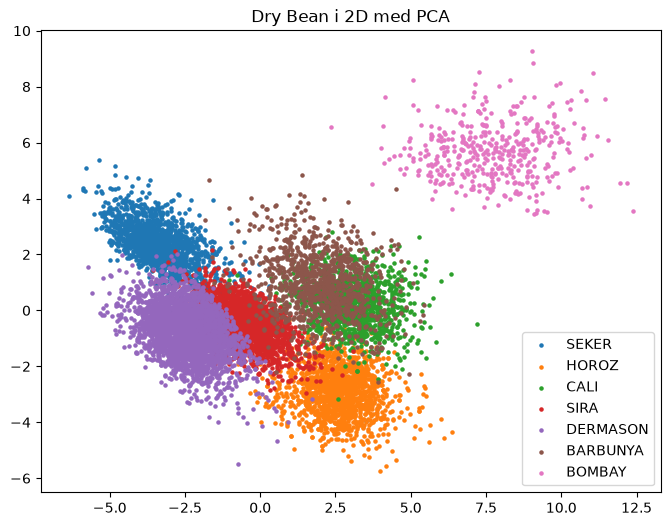

In [11]:
plt.figure(figsize=(8, 6))
for i in y_train.unique():
    maske = (y_train == i). values      # Sjekker om hver prikk er av type i
    plt.scatter(X_train_pca[maske, 0], X_train_pca[maske, 1], s=5, label=i)


plt.title("Dry Bean i 2D med PCA")
plt.legend()
plt.show() 

Merk at PCA ikke ser klassene. De legger vi til i etterkant,for å se om bønnene havner hver for seg.

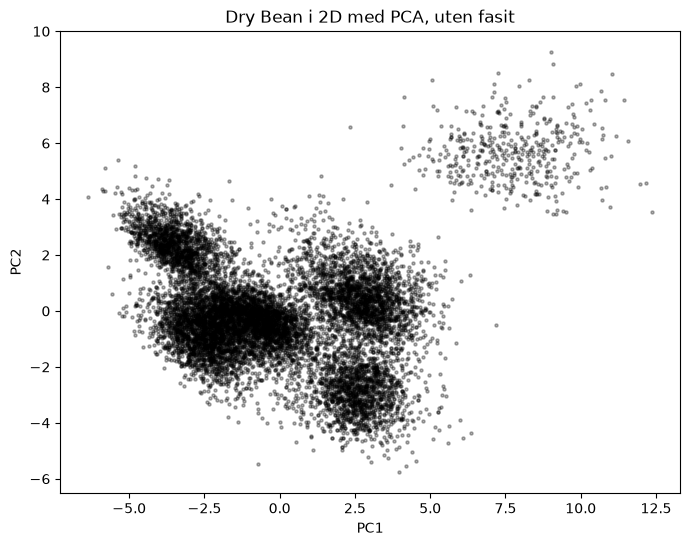

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], s=5, color="black", alpha=0.3)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Dry Bean i 2D med PCA, uten fasit")
plt.show()

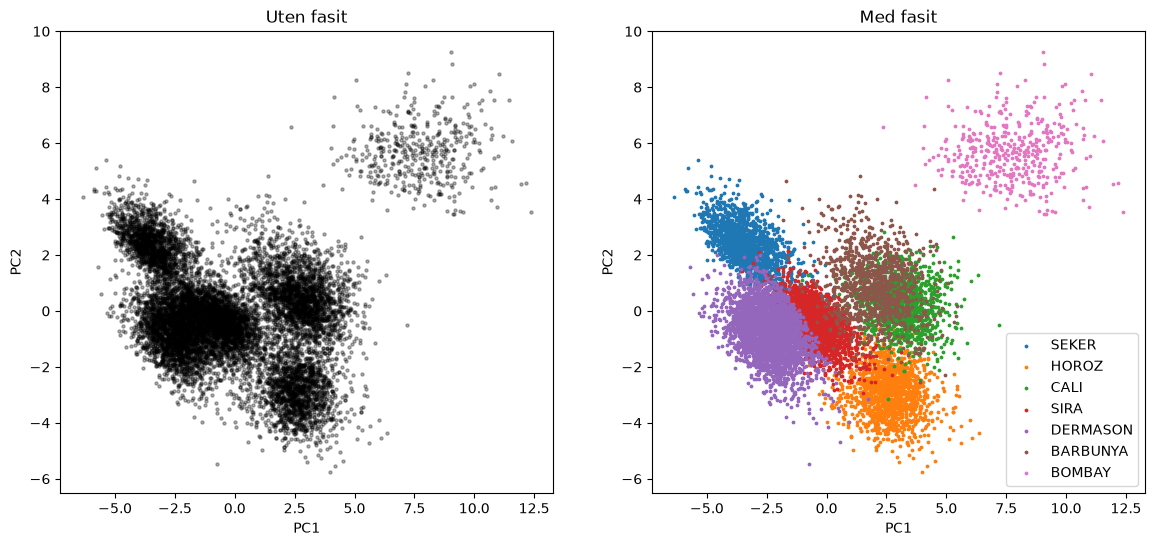

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Venstre: uten fasit
ax1.scatter(X_train_pca[:, 0], X_train_pca[:, 1], s=5, color="black", alpha=0.3)
ax1.set_title("Uten fasit")

# Høyre: farget etter bønnetype
for i in y_train.unique():
    maske = (y_train == i).values
    ax2.scatter(X_train_pca[maske, 0], X_train_pca[maske, 1], s=3, label=i)
ax2.set_title("Med fasit")
ax2.legend()

for ax in (ax1, ax2):
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.show()

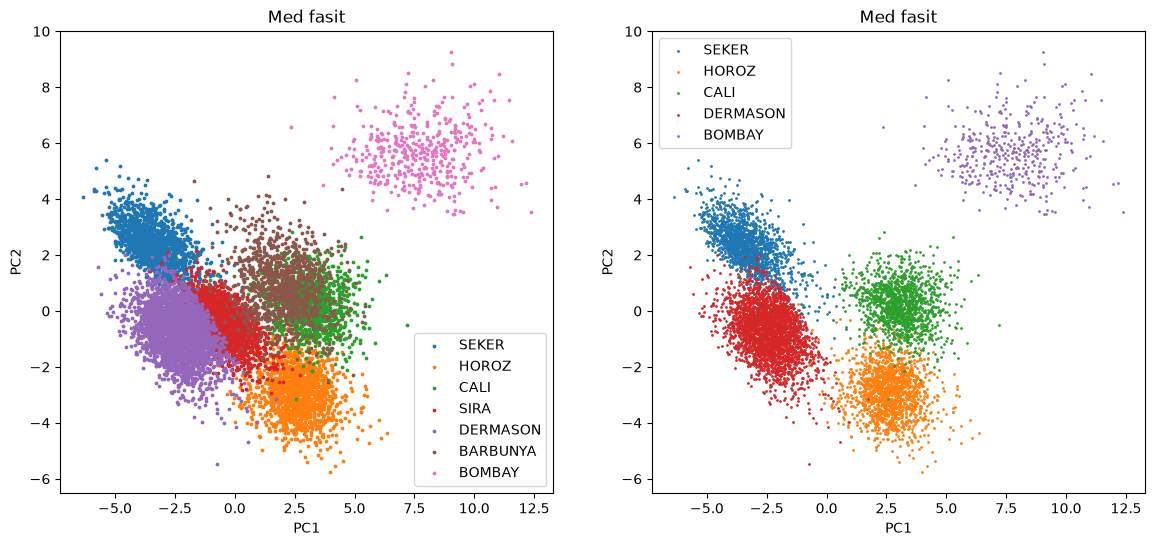

In [39]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for i in y_train.unique():
    maske = (y_train == i).values
    ax1.scatter(X_train_pca[maske, 0], X_train_pca[maske, 1], s=3, label=i)
ax1.set_title("Med fasit")
ax1.legend()


for i in y_train.unique():
    if i == "SIRA" or i == "BARBUNYA":
        continue
    maske = (y_train == i).values
    ax2.scatter(X_train_pca[maske, 0], X_train_pca[maske, 1], s=1, label=i)
ax2.set_title("Med fasit")
ax2.legend()

for ax in (ax1, ax2):
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.show()


### Test

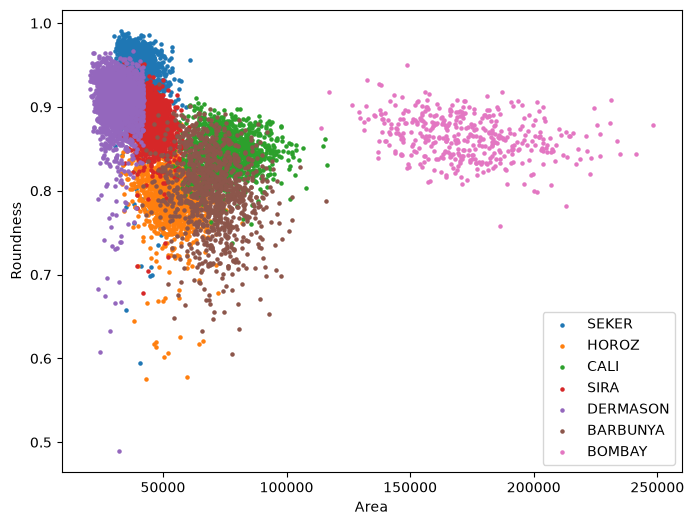

In [20]:
plt.figure(figsize=(8, 6))
for i in y_train.unique():
    maske = (y_train == i).values
    plt.scatter(X_train.loc[maske, "Area"], X_train.loc[maske, "Roundness"], s=5, label=i)
plt.xlabel("Area")
plt.ylabel("Roundness")
plt.legend()
plt.show()

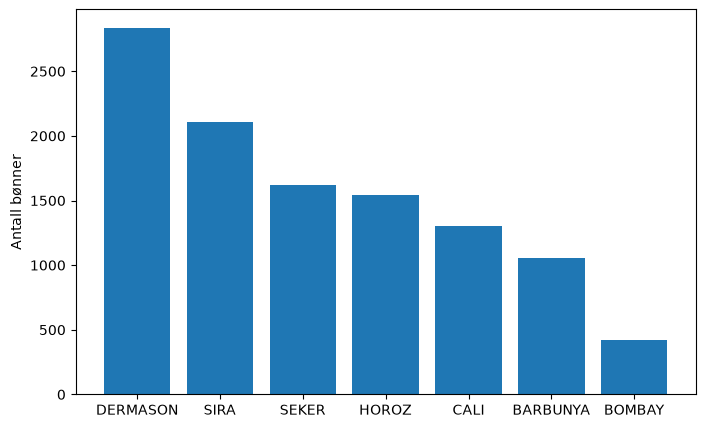

In [21]:
antall = y_train.value_counts()
plt.figure(figsize=(8, 5))
plt.bar(antall.index, antall.values)
plt.ylabel("Antall bønner")
plt.show()

Merk at det er veldig mye færre BOMBAY enn de andre, men det går fint, siden den ligger så langt unna i plottet, og er dermed lett å skille ut. Barybunya og cali er et større problem.

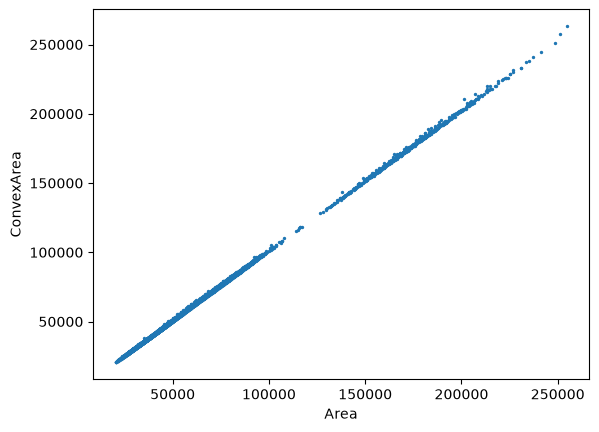

In [30]:
fig, ax = plt.subplots()
ax.scatter(X["Area"], X["ConvexArea"], s=2)
ax.set_xlabel("Area")
ax.set_ylabel("ConvexArea")
plt.show()

# K-mean

In [22]:


def avstand(p, q):          # Regner ut avstanden mellom to punkter i et flerdimensjonalt rom
    s = 0
    for i in range(len(p)):
        s += (p[i] - q[i])**2
    return math.sqrt(s)


def near_senter(punkt, sentre): # Finner hvilken gruppe et punkt tilhører
    best_idx = 0
    minste_avstand = avstand(punkt, sentre[0])
    for i in range(1, len(sentre)):
        d = avstand(punkt, sentre[i])
        if d < minste_avstand:
            minste_avstand = d
            best_idx = i
    return best_idx



# Funksjonen er laget av Claude, så jeg gikk gjennom nøye for å sikre god forståelse
def snitt(gruppe):          # Regner ut gjennomsnittspunktet til en gruppe i et flerdimensjonalt rom
    d = len(gruppe[0])              # Finner antall dimensjoner
    summer = [0] * d                # Lager en liste med en null for hver dimesjon 
    for punkt in gruppe:            # Går gjennom ett punkt om gangen
        for i in range(d):          
            summer[i] += punkt[i]   # Går gjennom hvert kordinat og legger til verdien til summen for sin dimensjon
    
    n = len(gruppe)                 # Teller over og finner antall punkter i gitt gruppe
    resultat = []                   
    for s in summer:
        resultat.append(s / n)      # Lager en tom liste og deler hver sum på antall punkter. (egentlig vanlig gjennomsnitt)
    return resultat                



def kmeans(punkter, k):                                     # Tar inn alle punkter (nested lists) og antall klynger vi vil ha
    sentre = random.sample(punkter, k)                      # Velger ut k forskjellige punkter til sentre

    while True:
        grupper = [[] for _ in range(k)]                    # Lager k tomme lister. En for hver gruppe.

        for punkt in punkter:                               # Går gjennom alle punktene og bruker near_senter for å finne hvilken gruppe punktet er nærmest
            i = near_senter(punkt, sentre)
            grupper[i].append(punkt)
        
        nye_sentre = []                                     
        for i in range(k):                                  # Går gjennom alle gruppene
            if len(grupper[i]) == 0:                        # Sikkerhetsfunksjon for tilfeller der en gruppe ikke fikk noen punkter
                nye_sentre.append(sentre[i])
            else:
                nye_sentre.append(snitt(grupper[i]))        # Setter det nye senteret som gjennomsnittet av gruppen 
        
        if nye_sentre == sentre:                            # Hvis gruppene ikke flytter på seg sier vi oss ferdig
            return sentre, grupper

        sentre = nye_sentre



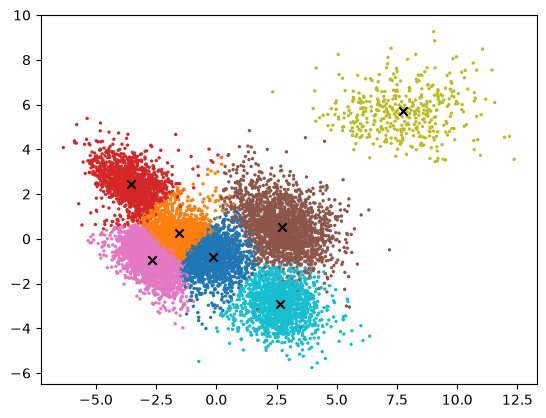

In [23]:

punkter = X_train_s.tolist()
sentre, grupper = kmeans(punkter, 7)

etiketter = [near_senter(p, sentre) for p in punkter]
sentre_pca = pca.transform(np.array(sentre))

plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=etiketter, s=2, cmap="tab10")
plt.scatter(sentre_pca[:, 0], sentre_pca[:, 1], c="black", marker="x")
plt.show()

Tabellen under viser hvor mange av hver bønnetype som havner i hver gruppe (Bortover (0-6) er de forskjellige klassene som dataene har delt seg på, mens tallene under er hvor mange av bønnene som havnet i den klassen). Vi kan altså se på tabellen, og se hvilket tall som er størst under hvert tall (0-6), og bruke det for å si hvilken klasse den k gruppa representerer

In [24]:
random.seed(42)     # Gir samme startsentre hver gang, så resultatet ikke endrer seg

sentre, grupper = kmeans(punkter, 7)
etiketter = [near_senter(p, sentre) for p in punkter]

tabell = pd.crosstab(y_train.values, etiketter)
print(tabell)

col_0        0    1     2     3    4     5     6
row_0                                           
BARBUNYA   103    0    11     6   40   897     0
BOMBAY       0  417     0     0    0     1     0
CALI        37    0     0    23    4  1240     0
DERMASON   226    0    84     5  602     1  1919
HOROZ       52    0     0  1411    3    74     2
SEKER       18    0  1409     0  187     2     5
SIRA      1233    0     6    32  800     9    29


## Albue metoden

1 174208
2 133065
3 75690
4 61095
5 49440
6 44323
7 42525
8 41174
9 34239
10 32956


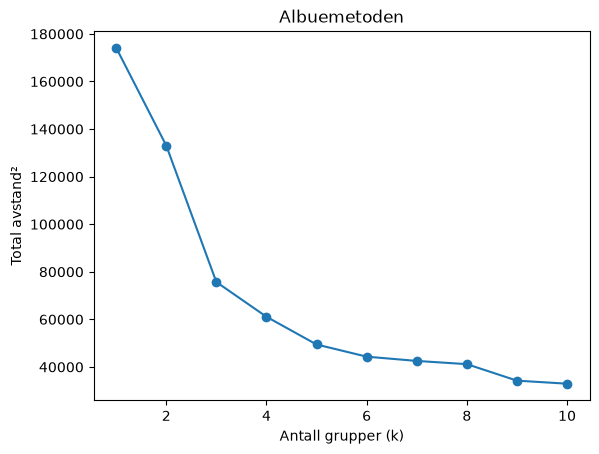

In [25]:
def total_avstand(sentre, grupper):     # Summen av (avstand til eget senter)² for alle punkter
    s = 0
    for i in range(len(sentre)):
        for punkt in grupper[i]:
            s += avstand(punkt, sentre[i])**2
    return s


k_verdier = range(1, 11)
resultater = []

for k in k_verdier:
    random.seed(42)
    sentre, grupper = kmeans(punkter, k)
    resultater.append(total_avstand(sentre, grupper))
    print(k, round(resultater[-1]))    # Viser fremgangen underveis

plt.plot(k_verdier, resultater, marker="o")
plt.xlabel("Antall grupper (k)")
plt.ylabel("Total avstand²")
plt.title("Albuemetoden")
plt.show()

In [26]:
def kmeans_beste(punkter, k, forsok):           # Kjører k-means flere ganger og beholder beste resultat
    beste_avstand = None

    for _ in range(forsok):
        sentre, grupper = kmeans(punkter, k)    # Nye tilfeldige startsentre hver gang
        d = total_avstand(sentre, grupper)

        if beste_avstand is None or d < beste_avstand:
            beste_avstand = d
            beste_sentre = sentre
            beste_grupper = grupper

    return beste_sentre, beste_grupper, beste_avstand

1 174208
2 103909
3 75690
4 61095
5 49440
6 43875
7 38850
8 36166
9 35653
10 31651


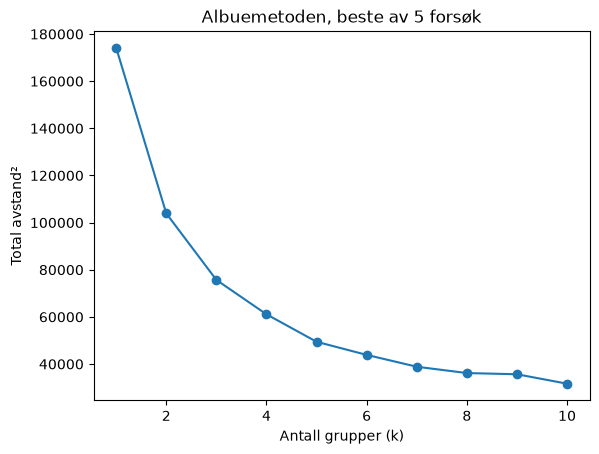

In [27]:
random.seed(42)
k_verdier = range(1, 11)
resultater = []

for k in k_verdier:
    sentre, grupper, d = kmeans_beste(punkter, k, forsok=5)
    resultater.append(d)
    print(k, round(d))

plt.plot(k_verdier, resultater, marker="o")
plt.xlabel("Antall grupper (k)")
plt.ylabel("Total avstand²")
plt.title("Albuemetoden, beste av 5 forsøk")
plt.show()

Albuepunktet gir ingen veldig tydelig albue, men kurven forandrer oppførsel litt på k=7 (endringen i varians blir mindre og mindre for alle punktene, med unntak av for punkt 7 og 10, noe som er litt rart).

In [28]:
random.seed(42)
sentre, grupper, d = kmeans_beste(punkter, 7, forsok=5)
etiketter = [near_senter(p, sentre) for p in punkter]

tabell = pd.crosstab(y_train.values, etiketter)
print(tabell)

col_0        0     1     2    3    4     5     6
row_0                                           
BARBUNYA    14     7   910    0   32     0    94
BOMBAY       0     0     1  417    0     0     0
CALI         0    20  1059    0  199     0    26
DERMASON    93     7     0    0   10  2347   380
HOROZ        0  1332    24    0  147     2    37
SEKER     1494     0     0    0    3    45    79
SIRA        17    53     5    0   19   164  1851


Hvis hver gruppe betyr den typen det er flest av i den (med unntak av grupp 2, for å unngå overlapp, selv om det egentlig er "feil" måte å jobbe på), kan vi telle hvor mange som havner riktig: 1494 + 1332 + 910 (eller 1059) + 417 + 199 + 2347 + 1851 = 8550

8550 / 10888 = 0,785 så 78,5% nøyaktighet

# Logistisk regresojn

Hva vi gjør:
1. Setter opp syv poengsummer (en for hver bønne).
2. Gjør om hver poengsum til sannsynligheter (softmax), for å finne ut av hvilken bønnetype.
3. Måler hvor feil sannsynligheten er
4. Vi justerer vektene litt for å få tapet ned (og gjentar mange ganger)

In [2]:
klasser = sorted(y_train.unique())
klasse_til_tall = {navn: i for i, navn in enumerate(klasser)}

y_train_tall = y_train.map(klasse_til_tall).values
y_test_tall = y_test.map(klasse_til_tall).values

print(klasse_til_tall)
print(y_train.values[:3], y_train_tall[:3])

NameError: name 'y_train' is not defined

# Megateit testing og eksperimentering

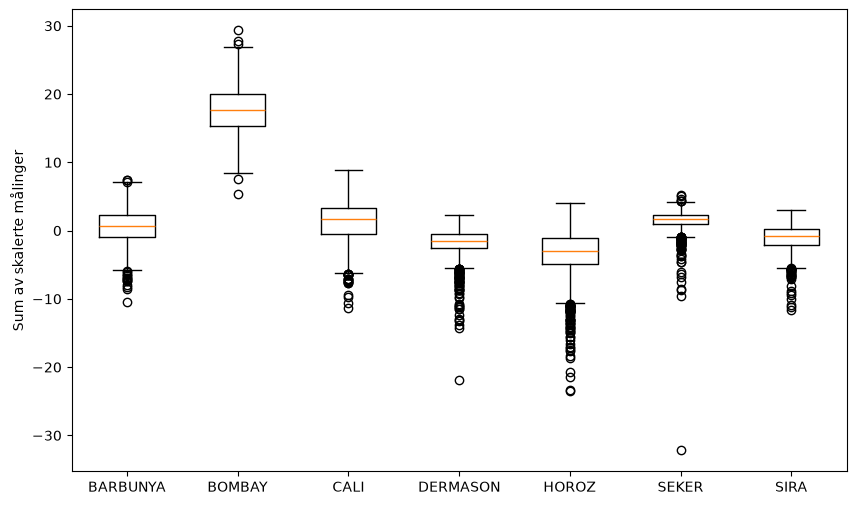

In [29]:
typer = sorted(y_train.unique())
summen = X_train_s.sum(axis=1)       # Én sum per bønne
data = [summen[(y_train == t).values] for t in typer]

plt.figure(figsize=(10, 6))
plt.boxplot(data)
plt.xticks(range(1, 8), typer)
plt.ylabel("Sum av skalerte målinger")
plt.show()

In [31]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# https://www.geeksforgeeks.org/machine-learning/supervised-machine-learning/
modeller = {
    "Logistisk regresjon": LogisticRegression(max_iter=1000),
    "k nærmeste naboer": KNeighborsClassifier(),
    "Beslutningstre": DecisionTreeClassifier(random_state=42),
    "Random forest": RandomForestClassifier(random_state=42),
    "Naiv Bayes": GaussianNB(),
    "SVM": SVC(),   # Support Vector Machines
    "Nevralt nettverk": MLPClassifier(max_iter=1000, random_state=42),
}

for navn, modell in modeller.items():
    start = time.time()
    modell.fit(X_train_s, y_train)
    treff = modell.score(X_test_s, y_test)
    tid = time.time() - start
    print(f"{navn:20} {treff*100:.1f} %   ({tid:.1f} s)")

Logistisk regresjon  92.1 %   (0.2 s)
k nærmeste naboer    91.7 %   (0.1 s)
Beslutningstre       89.2 %   (0.2 s)
Random forest        92.1 %   (2.0 s)
Naiv Bayes           89.8 %   (0.0 s)
SVM                  92.2 %   (0.6 s)
Nevralt nettverk     92.8 %   (5.4 s)
